# Does AC Milan Have a Bigger Home Advantage Than Other Serie A Teams?

I'm a passionate AC Milan fan, and I wanted to find out whether Milan benefits more from playing at home than other Serie A teams do.


The data is from football-data.co.uk (https://football-data.co.uk/italym.php),
which publishes one free file for each Serie A season. I used 21 seasons from 2005/06 to 2025/26. After removing 5 blank rows, there are 7,980 matches, 380 in each season. The notebook reads the files directly from the website, so no data file is included here.


I measured home advantage as points per game at home minus points per game away(3 points for a win, 1 for a draw, 0 for a loss), and compared Milan with the other teams that played at least 10 seasons in the data, using the median gap as the typical value.

In [13]:
import pandas as pd

seasons = ["0506","0607","0708","0809","0910","1011","1112","1213","1314","1415",
           "1516","1617","1718","1819","1920","2021","2122","2223","2324","2425","2526"]

frames = []
for s in seasons:
    url = f"https://football-data.co.uk/mmz4281/{s}/I1.csv"
    d = pd.read_csv(url, encoding="latin-1")
    d["Season"] = s
    frames.append(d[["Season", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR"]])

df = pd.concat(frames, ignore_index=True)
print(df.shape)
df.head()

(7985, 6)


,Season,HomeTeam,AwayTeam,FTHG,FTAG,FTR
0,0506,Fiorentina,Sampdoria,2.0,1.0,H
1,0506,Livorno,Lecce,2.0,1.0,H
2,0506,Ascoli,Milan,1.0,1.0,D
3,0506,Inter,Treviso,3.0,0.0,H
4,0506,Juventus,Chievo,1.0,0.0,H


**Loading the data**

* The code reads or has one file per season (2005/06 to 2025/26) from the website football-data.co.uk and it contains six columns: season, home team, away team, home goals, away goals, and the result.

* The table consists of 7,985 rows, which is 5 more than the 7,980 I expected it to turn out ( 21 seasons x 380 matches). The upcoming cell explains why.

In [14]:
print(df.groupby("Season").size())
print(df.isna().sum())

Season
0506    380
0607    380
0708    380
0809    380
0910    380
1011    380
1112    380
1213    383
1314    380
1415    381
1516    381
1617    380
1718    380
1819    380
1920    380
2021    380
2122    380
2223    380
2324    380
2425    380
2526    380
dtype: int64
Season      0
HomeTeam    5
AwayTeam    5
FTHG        5
FTAG        5
FTR         5
dtype: int64


In [15]:
df = df.dropna().reset_index(drop=True)
print(df.shape)
print(df.groupby("Season").size().unique())
print(sorted(df["HomeTeam"].unique()))

(7980, 6)
[380]
['Ascoli', 'Atalanta', 'Bari', 'Benevento', 'Bologna', 'Brescia', 'Cagliari', 'Carpi', 'Catania', 'Cesena', 'Chievo', 'Como', 'Cremonese', 'Crotone', 'Empoli', 'Fiorentina', 'Frosinone', 'Genoa', 'Inter', 'Juventus', 'Lazio', 'Lecce', 'Livorno', 'Messina', 'Milan', 'Monza', 'Napoli', 'Novara', 'Palermo', 'Parma', 'Pescara', 'Pisa', 'Reggina', 'Roma', 'Salernitana', 'Sampdoria', 'Sassuolo', 'Siena', 'Spal', 'Spezia', 'Torino', 'Treviso', 'Udinese', 'Venezia', 'Verona']


**Removing empty rows**

* Three seasons contained more than 380 rows: 2012/13 (383), 2014/15 (381), and 2015/16 (381), the 5 error rows were empty in every single column, so they appeared as blank lines in the files and not real matches.

* I deleted them because they had no value, the table now has 7,980 matches, and each season has 380 (20 teams playing 38 games each).

In [16]:
home = pd.DataFrame({"Season": df["Season"], "Team": df["HomeTeam"], "Venue": "Home",
                     "GF": df["FTHG"], "GA": df["FTAG"]})
away = pd.DataFrame({"Season": df["Season"], "Team": df["AwayTeam"], "Venue": "Away",
                     "GF": df["FTAG"], "GA": df["FTHG"]})

games = pd.concat([home, away], ignore_index=True)
games["GD"] = games["GF"] - games["GA"]
games["Points"] = 3 * (games["GF"] > games["GA"]) + 1 * (games["GF"] == games["GA"])

print(games.shape)
print(games[games["Team"] == "Milan"].shape)
games.head()

(15960, 7)
(798, 7)


,Season,Team,Venue,GF,GA,GD,Points
0,0506,Fiorentina,Home,2.0,1.0,1.0,3
1,0506,Livorno,Home,2.0,1.0,1.0,3
2,0506,Ascoli,Home,1.0,1.0,0.0,1
3,0506,Inter,Home,3.0,0.0,3.0,3
4,0506,Juventus,Home,1.0,0.0,1.0,3


**Turning matches to team rows**

* Each match now turns to two rows, one each for the home and away team, so every team's home and away matches are in this table. It consists of (GF) goals scored for the team and (GA) goals conceded, the goal difference (GD), and points earned.

* Points: 3 for a win, 1 for a draw, and 0 for a loss. The table consists of 15,960 rows and Milan has 798 of those rows.

In [17]:
games.head(20)

,Season,Team,Venue,GF,GA,GD,Points
0,0506,Fiorentina,Home,2.0,1.0,1.0,3
1,0506,Livorno,Home,2.0,1.0,1.0,3
2,0506,Ascoli,Home,1.0,1.0,0.0,1
3,0506,Inter,Home,3.0,0.0,3.0,3
4,0506,Juventus,Home,1.0,0.0,1.0,3
5,0506,Lazio,Home,1.0,0.0,1.0,3
6,0506,Parma,Home,1.0,1.0,0.0,1
7,0506,Reggina,Home,0.0,3.0,-3.0,0
8,0506,Siena,Home,2.0,1.0,1.0,3
9,0506,Udinese,Home,1.0,0.0,1.0,3


In [18]:
h = games[games["Venue"] == "Home"].groupby("Team")
a = games[games["Venue"] == "Away"].groupby("Team")

table = pd.DataFrame({"HomeGames": h.size(),
                      "HomePPG": h["Points"].mean(),
                      "AwayPPG": a["Points"].mean()})
table["Gap"] = table["HomePPG"] - table["AwayPPG"]
table = table[table["HomeGames"] >= 190].sort_values("Gap", ascending=False)
print(table.round(2))

            HomeGames  HomePPG  AwayPPG   Gap
Team                                         
Palermo           209     1.62     0.89  0.74
Cagliari          361     1.38     0.78  0.59
Sampdoria         323     1.51     0.92  0.59
Fiorentina        399     1.81     1.24  0.57
Roma              399     2.13     1.57  0.56
Genoa             342     1.45     0.90  0.56
Parma             266     1.38     0.87  0.51
Empoli            209     1.29     0.84  0.45
Napoli            361     2.10     1.67  0.43
Juventus          380     2.31     1.88  0.43
Lazio             399     1.85     1.42  0.43
Inter             399     2.20     1.78  0.42
Udinese           399     1.47     1.05  0.41
Torino            323     1.44     1.05  0.39
Atalanta          361     1.69     1.33  0.36
Bologna           323     1.40     1.04  0.36
Milan             399     2.01     1.67  0.34
Verona            209     1.18     0.85  0.33
Chievo            247     1.27     0.94  0.33
Sassuolo          228     1.33    

**Milan's home advantage rank**

* Out of the 20 qualified teams (teams with at least 10 seasons), Milan's home advantage gap is 0.34 points per game, reason is from 2.01 at home and 1.67 away.

* This places Milan in the lower section of the table, ranking 17th out of 20 for home advantage, which is lower than the leagues median of 0.43.

In [19]:
table["Rank"] = table["Gap"].rank(ascending=False)
print(table.loc["Milan"])
print("Teams:", len(table))
print("Mean gap:", round(table["Gap"].mean(), 2))
print("Median gap:", round(table["Gap"].median(), 2))

HomeGames    399.000000
HomePPG        2.012531
AwayPPG        1.669173
Gap            0.343358
Rank          17.000000
Name: Milan, dtype: float64
Teams: 20
Mean gap: 0.45
Median gap: 0.43


In [20]:
import numpy as np

rng = np.random.default_rng(42)
mh = games[(games["Team"] == "Milan") & (games["Venue"] == "Home")]["Points"].values
ma = games[(games["Team"] == "Milan") & (games["Venue"] == "Away")]["Points"].values

gaps = []
for _ in range(10000):
    gaps.append(rng.choice(mh, len(mh)).mean() - rng.choice(ma, len(ma)).mean())

low, high = np.percentile(gaps, [2.5, 97.5])
print("Milan gap:", round(mh.mean() - ma.mean(), 2))
print("95% interval:", round(low, 2), "to", round(high, 2))
print("League median gap:", round(table["Gap"].median(), 2))

Milan gap: 0.34
95% interval: 0.16 to 0.52
League median gap: 0.43


**Milan's gap, is it just luck?**

* To verify this, I re-drew the home and away match results for Milan 10,000 times and measured the gap every time. The gap from Milan's true results are 0.34, and 95% of the re-drawn gaps run from 0.16 to 0.52.

* The median gap of the league (0.43) is inside that range. This means that Milan's gap is lower than most Serie A teams, but I can't rule out the possibility of luck, so there isn't a clear difference between Milan and other Serie A teams.

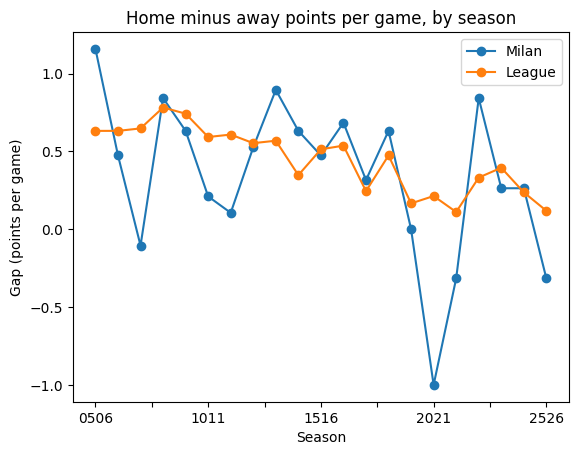

        Milan  League
Season               
0506     1.16    0.63
0607     0.47    0.63
0708    -0.11    0.65
0809     0.84    0.78
0910     0.63    0.74
1011     0.21    0.59
1112     0.11    0.61
1213     0.53    0.55
1314     0.89    0.57
1415     0.63    0.35
1516     0.47    0.51
1617     0.68    0.54
1718     0.32    0.24
1819     0.63    0.47
1920     0.00    0.17
2021    -1.00    0.21
2122    -0.32    0.11
2223     0.84    0.33
2324     0.26    0.39
2425     0.26    0.24
2526    -0.32    0.12


In [21]:
import matplotlib.pyplot as plt

def season_gap(g):
    h = g[g["Venue"] == "Home"].groupby("Season")["Points"].mean()
    a = g[g["Venue"] == "Away"].groupby("Season")["Points"].mean()
    return h - a

milan_gap = season_gap(games[games["Team"] == "Milan"])
league_gap = season_gap(games)

pd.DataFrame({"Milan": milan_gap, "League": league_gap}).plot(marker="o")
plt.title("Home minus away points per game, by season")
plt.ylabel("Gap (points per game)")
plt.show()
print(pd.DataFrame({"Milan": milan_gap, "League": league_gap}).round(2))

**has the gap changed over time?**

* The league-wide home advantage fell by a lot: it was averaging about 0.69 points per game in the first five seasons (05/06 to 09/10) and then it fell to 0.22 in the last seven seasons (19/20 to 25/26).

* Milan's line chaotically jumps around much more than the league's, that's because each season has 19 home and away matches so the results are bound to be over the place. Milan was above the league line in 9 out of 21 seasons and 12 below it, which fits earlier results of no clear difference.

In [22]:
frames2 = []
for s in seasons:
    url = f"https://football-data.co.uk/mmz4281/{s}/I1.csv"
    d = pd.read_csv(url, encoding="latin-1")
    d["Season"] = s
    frames2.append(d)

full = pd.concat(frames2, ignore_index=True)
full = full.dropna(subset=["HomeTeam"])

print("Attendance column exists:", "Attendance" in full.columns)
if "Attendance" in full.columns:
    print(full.groupby("Season")["Attendance"].count())

Attendance column exists: False


**Can I test the Covid seasons**

* I reloaded all season files with every column and checked for attendance. The files had no attendance column, so I can't test whether empty stadiums affected home advantage during Covid.

In [23]:
recent = games[games["Season"] >= "1920"]
mh = recent[(recent["Team"] == "Milan") & (recent["Venue"] == "Home")]["Points"].values
ma = recent[(recent["Team"] == "Milan") & (recent["Venue"] == "Away")]["Points"].values

rng = np.random.default_rng(42)
gaps = [rng.choice(mh, len(mh)).mean() - rng.choice(ma, len(ma)).mean() for _ in range(10000)]
low, high = np.percentile(gaps, [2.5, 97.5])
league = recent[recent["Venue"] == "Home"]["Points"].mean() - recent[recent["Venue"] == "Away"]["Points"].mean()

print("Milan gap 2019/20-2025/26:", round(mh.mean() - ma.mean(), 2))
print("95% interval:", round(low, 2), "to", round(high, 2))
print("League gap, same seasons:", round(league, 2))

Milan gap 2019/20-2025/26: -0.04
95% interval: -0.34 to 0.27
League gap, same seasons: 0.22


 **Milan in the last seven seasons**

 * from (19/20) to (25/26) Milan's gap was -0.04, and the 95% interval runs from -0.34 to 0.27. The league's gap in those seasons which is 0.22, is inside that range, so I still can't rule out the possibility of luck.

 * I picked this window after seeing the chart and its numbers, and this is an exploratory check by a Milan fan and not a planned test.

In [24]:
def gap(g):
    return g[g["Venue"] == "Home"]["Points"].mean() - g[g["Venue"] == "Away"]["Points"].mean()

early = games[games["Season"] <= "0910"]
late = games[games["Season"] >= "1920"]
print("League gap 2005/06-2009/10:", round(gap(early), 2))
print("League gap 2019/20-2025/26:", round(gap(late), 2))

League gap 2005/06-2009/10: 0.69
League gap 2019/20-2025/26: 0.22


**Conclusion and limitations**

* Main finding: there wasn't any clear evidence that indicates Milan's home advantage is larger or smaller than Serie A team's. Over 21 seasons, Milan earned 0.34 more points at home per game than away, ranking 17th out of 20 teams, also the 95% interval (0.16 to 0.52) includes the league median of 0.43.

* The larger pattern was league-wide: home advantage from 0.69 points per game in 2005/06 to 2009/10 to about 0.22 in 2019/20 to 2025/26. In the last seven seasons Milan's gap is almost to exact zero (-0.04), but that window was also chosen after looking at the chart, so I can't rule out the possibility of luck.

* Limits: I was limited by many factors such as (goals and results) and there wasn't any attendance data, and I only tested Milan's gap against chance, so the 17th ranking isn't quite solidified.